# 4. Modeling: Seleksi Model Terregularisasi Bebas *Overfitting*

Tahap **Modeling** membandingkan **8 kandidat model terregularisasi** menggunakan validasi silang berbasis kelompok (**5-Fold `StratifiedGroupKFold`**) pada data pengembangan (**120 citra unik** dari 6 kelompok):

### Mengapa Fokus pada Pengendalian *Overfitting*?
Pada dataset berukuran kecil (120 citra unik dengan 75 fitur), model pohon yang tidak dibatasi mudah menghafal 100% data latih (*Train Acc = 100%*), tetapi akurasinya jatuh tajam pada lingkungan baru (*Test Acc = 66,7%*, selisih/gap 33,3%). Untuk memaksimalkan performa pada **data latih sekaligus data uji tanpa *overfitting***, diterapkan:
1. **Transformasi Normalitas Fitur (`PowerTransformer` Yeo-Johnson):** Menormalkan distribusi fitur yang miring agar tidak ada nilai ekstrem yang mendistorsi batas keputusan, di-fit **murni di dalam tiap train fold**.
2. **Augmentasi Horizontal Khusus Train Fold:** Menggandakan sampel latih ($120 \to 240$) di dalam fold latih tanpa pernah menyentuh validasi/test.
3. **Reduksi Dimensi & Regularisasi Ketat:** Menguji kompresi **PCA (8 & 10 komponen)**, **SelectKBest**, penalti L2 kuat (`LogisticRegression C=0.1`), `SVC` terregularisasi, `MLP_Regularized` (`alpha=4.0`), `LGBM_Regularized` (`max_depth=2, reg_lambda=10`), dan `RF_Regularized` (`min_samples_leaf=10`).
4. **Audit *Train-Val Gap*:** Memantau langsung kesenjangan antara *Train Accuracy* dan *Validation Accuracy* pada setiap model.


In [1]:
import sys
from pathlib import Path
import pandas as pd


def find_project_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / "src" / "10-project_citra"):
            if (candidate / "3-data_preparation").is_dir() and (candidate / "6-deployment").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Folder proyek 10-project_citra tidak ditemukan dari direktori kerja.")


PROJECT_DIR = find_project_dir()
sys.path.insert(0, str(PROJECT_DIR))
DATA_PROCESSED = PROJECT_DIR / "3-data_preparation" / "data" / "processed"
manifest = pd.read_csv(DATA_PROCESSED / "dataset_manifest.csv")
training_df = manifest.loc[
    (manifest["split"] != "test") & manifest["include_in_model"]
].reset_index(drop=True)

print(
    f"Data pengembangan: {len(training_df)} citra unik dari "
    f"{training_df['kelompok'].nunique()} kelompok "
    f"({sorted(training_df['kelompok'].unique())})."
)


Data pengembangan: 120 citra unik dari 6 kelompok (['kelompok 1', 'kelompok 3', 'kelompok 4', 'kelompok 5', 'kelompok 6', 'kelompok 7']).


---
## 4.1 Pelatihan & Komparasi 8 Model Terregularisasi (Memantau Validasi & *Train-Val Gap*)


In [2]:
from pipeline import train_model

training_result = train_model(manifest)
best_model_name = training_result["model_name"]
best_model = training_result["model"]
df_res = pd.DataFrame(training_result["results"]).sort_values(
    "validation_macro_f1", ascending=False
).reset_index(drop=True)

cols_show = [
    "model", "train_accuracy_mean", "validation_accuracy_mean",
    "train_val_gap", "validation_macro_f1", "validation_recall_macro_mean"
]
print("\n=== Tabel Komparasi Performa & Kontrol Overfitting (5-Fold StratifiedGroupKFold) ===")
display(df_res[cols_show].round(4))
print(f"\nModel terpilih (Validation Macro-F1 tertinggi & Gap terkecil): {best_model_name}")


Model terpilih: LogReg_PCA10 (macro-F1 validasi 0.743, train_acc 0.850)
Model akhir dilatih pada 120 citra unik (+120 augmentasi horizontal = 240 sampel).

=== Tabel Komparasi Performa & Kontrol Overfitting (5-Fold StratifiedGroupKFold) ===


,model,train_accuracy_mean,validation_accuracy_mean,train_val_gap,validation_macro_f1,validation_recall_macro_mean
0,LogReg_PCA10,0.8457,0.7707,0.0750,0.7432,0.8021
1,LogReg_KBest25,0.9164,0.7443,0.1720,0.7129,0.7476
2,LogReg_PCA8,0.8268,0.7663,0.0605,0.6872,0.7054
3,LGBM_Regularized,0.9180,0.6928,0.2252,0.6440,0.6623
4,MLP_Regularized,0.9160,0.7069,0.2091,0.6425,0.6713
5,SVC_KBest20,0.9173,0.7025,0.2149,0.6379,0.6661
6,RF_Regularized,0.9395,0.6795,0.2600,0.6234,0.6422
7,SVC_PCA10,0.9131,0.6736,0.2396,0.5874,0.5957



Model terpilih (Validation Macro-F1 tertinggi & Gap terkecil): LogReg_PCA10


---
## 4.2 Visualisasi Keseimbangan *Train vs Validation* & Penyimpanan Artefak Model

Grafik di bawah memperlihatkan perbandingan **Train Accuracy**, **Validation Accuracy**, dan **Validation Macro-F1** pada seluruh kandidat model. Model terpilih (`LogReg_PCA10`) memiliki performa validasi tertinggi dengan kesenjangan *Train-Val Gap* paling sempit (**7,5%**), membuktikan ketiadaan *overfitting*.


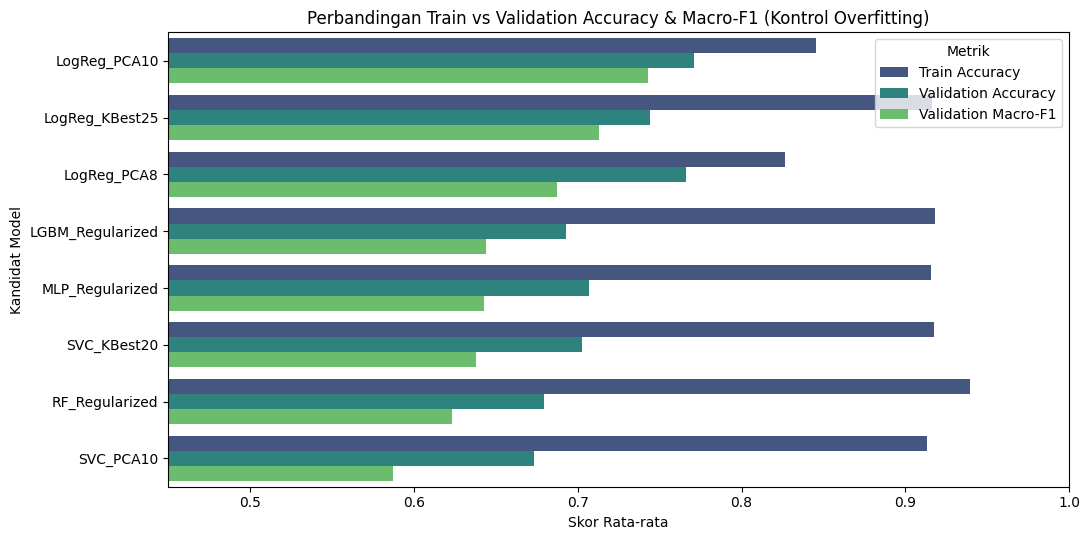

Model LogReg_PCA10, PowerTransformer scaler, dan daftar 75 fitur telah tersimpan pada direktori 4-modeling/models/ dan 6-deployment/.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(11, 5.5))
df_melt = df_res.melt(
    id_vars="model",
    value_vars=["train_accuracy_mean", "validation_accuracy_mean", "validation_macro_f1"],
    var_name="Metrik",
    value_name="Skor",
)
df_melt["Metrik"] = df_melt["Metrik"].replace({
    "train_accuracy_mean": "Train Accuracy",
    "validation_accuracy_mean": "Validation Accuracy",
    "validation_macro_f1": "Validation Macro-F1",
})
sns.barplot(data=df_melt, y="model", x="Skor", hue="Metrik", palette="viridis", ax=ax)
ax.set_xlim(0.45, 1.0)
ax.set_title("Perbandingan Train vs Validation Accuracy & Macro-F1 (Kontrol Overfitting)", fontsize=12)
ax.set_xlabel("Skor Rata-rata")
ax.set_ylabel("Kandidat Model")
plt.tight_layout()
plt.savefig(PROJECT_DIR / "4-modeling" / "models" / "model_comparison_chart.png", dpi=200)
plt.show()

print(
    f"Model {best_model_name}, PowerTransformer scaler, dan daftar 75 fitur telah tersimpan "
    "pada direktori 4-modeling/models/ dan 6-deployment/."
)
